In [ ]:
import os

# Ensure `langchain-core` is managed by `langgraph` and other packages.
!pip install -U langchain-community langchain-experimental langchain_google_genai

### Build a Simple Workflow or Graph Using LangGraph

**State**
First, define the State of the graph.

The State schema serves as the input schema for all Nodes and Edges in the graph.

Let's use the TypedDict class from python's typing module as our schema, which provides type hints for the keys.

In [ ]:
from typing_extensions import TypedDict
class State(TypedDict):
    graph_info:str

**Nodes** :
Nodes are just python functions.

The first positional argument is the state, as defined above.

Because the state is a TypedDict with schema as defined above, each node can access the key, graph_state, with state['graph_state'].

Each node returns a new value of the state key graph_state.

By default, the new value returned by each node will override the prior state value.

In [ ]:
def start_play(state:State):
    print("Start_Play node has been called")
    return {"graph_info":state['graph_info'] + " I am planning to play"}

def cricket(state:State):
    print("My Cricket node has been called")
    return {"graph_info":state['graph_info'] + " Cricket"}

def badminton(state:State):
    print("My badminton node has been called")
    return {"graph_info":state['graph_info'] + " Badminton"}

In [ ]:
import random
from typing import Literal

def random_play(state:State)-> Literal['cricket','badminton']:
    graph_info=state['graph_info']

    if random.random()>0.5:
        return "cricket"
    else:
        return "badminton"

**Graph Construction**
Now, we build the graph from our components defined above.

The StateGraph class is the graph class that we can use.

First, we initialize a StateGraph with the State class we defined above.

Then, we add our nodes and edges.

We use the START Node, a special node that sends user input to the graph, to indicate where to start our graph.

The END Node is a special node that represents a terminal node.

Finally, we compile our graph to perform a few basic checks on the graph structure.

We can visualize the graph as a Mermaid diagram.

In [ ]:
!pip install -U langgraph langgraph-prebuilt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.0/256.0 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.4/162.4 kB 12.9 MB/s eta 0:00:00
  Attempting uninstall: langgraph-sdk
    Found existing installation: langgraph-sdk 0.4.5
    Uninstalling langgraph-sdk-0.4.5:
      Successfully uninstalled langgraph-sdk-0.4.5
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.12
    Uninstalling langgraph-1.2.12:
      Successfully uninstalled langgraph-1.2.12


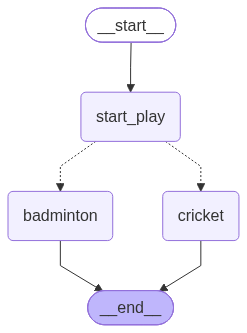

In [ ]:
from IPython.display import Image,display
from langgraph.graph import StateGraph,START,END

## Build Graph
graph=StateGraph(State)

## Adding the nodes
graph.add_node("start_play",start_play)
graph.add_node("cricket",cricket)
graph.add_node("badminton",badminton)

## Schedule the flow of the graph

graph.add_edge(START,"start_play")
graph.add_conditional_edges("start_play",random_play)
graph.add_edge("cricket",END)
graph.add_edge("badminton",END)

## Compile the graph
graph_builder=graph.compile()

## View
display(Image(graph_builder.get_graph().draw_mermaid_png()))

**GRAPH Invocation**

In [ ]:
graph_builder.invoke({"graph_info":"Hey My name is Alex"})

Start_Play node has been called
My Cricket node has been called


{'graph_info': 'Hey My name is Alex I am planning to play Cricket'}

### ReAct Agent Architecture

#### Aim
This is the intuition behind ReAct, a general agent architecture.

1. act - let the model call specific tools
2. observe - pass the tool output back to the model
3. reason - let the model reason about the tool output to decide what to do next (e.g., call another tool or just respond directly)


In [ ]:
import os
from google.colab import userdata

os.environ["GOOGLE_API_KEY"]=userdata.get('gemini_key')
#genai.configure(api_key=userdata.get('gemini_key'))

from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

/tmp/ipykernel_4266/3397247015.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [ ]:
import os
from google.colab import userdata

# To enable tracing by Langsmith for compiled graphs
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_API_KEY"] = userdata.get('Langsmith_key')
os.environ["LANGCHAIN_PROJECT"] = "Academy_Langgraph"

In [ ]:
!pip install arxiv==1.4.0

api_wrapper_arxiv=ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)
print(arxiv.name)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 2.5 MB/s eta 0:00:00
arxiv


In [ ]:
#arxiv.invoke("Attention iss all you need")

In [ ]:
import os

!pip install wikipedia

api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

In [ ]:
#wiki.invoke("What is machine learning")

In [ ]:
### Custom Functions
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

# This will be a tool
def add(a: int, b: int) -> int:
    """Adds a and b.

    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.

    Args:
        a: first int
        b: second int
    """
    return a / b


In [ ]:
os.environ["TAVILY_API_KEY"]=userdata.get('tavily_key')

### Tavily Search Tool
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

In [ ]:
tavily.invoke("Provide me the recent AI news for Sep 29 2026")

In [ ]:
### Combine all the tools in the list

tools=[tavily,add,divide,multiply]

In [ ]:
## Initialize my LLM model

from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash-lite")

llm_with_tools=llm.bind_tools(tools)

In [ ]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News as on 29 Sep 2026")])

In [ ]:
#llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls
#llm_with_tools.invoke([HumanMessage(content=f"What is the theory of relativity")]).tool_calls
#llm_with_tools.invoke([HumanMessage(content=f"What is 2 plus 2?")]).tool_calls
#llm_with_tools.invoke([HumanMessage(content=f"top 2 articles on psychoanalysis")]).tool_calls

In [ ]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

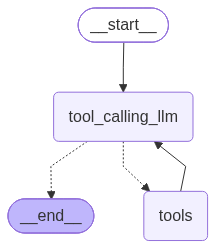

In [ ]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for April 27 2026,add 5 plus 5. Then multiply by 10. I also want to know about gravity and good articles on self attention")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for April 27 2026,add 5 plus 5. Then multiply by 10. I also want to know about gravity and good articles on self attention
================================== Ai Message ==================================

I am sorry, but I cannot provide news for April 27, 2026, as that date is in the future. I can provide current news, or news for a past date. I can also help with your other requests. Would you like me to proceed with those?


In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================
Tool Calls:
  tavily_search_results_json (0887a169-087f-4e28-a39a-3d1a20fcf3aa)
 Call ID: 0887a169-087f-4e28-a39a-3d1a20fcf3aa
  Args:
    query: What is machine learning
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "Machine learning - Wikipedia", "url": "https://en.wikipedia.org/wiki/Machine_learning", "content": "Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from data and generalize to unseen data, and thus perform tasks \"Task (computing)\") without being explicitly programmed.\n\nStatistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, fo

### Add Memory to Agents

In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="What is 5 plus 8")})
for m in messages['messages']:
    m.pretty_print()

NameError: name 'graph' is not defined

In [ ]:
messages=[HumanMessage(content="Divide that by 5")]
messages=graph.invoke({"messages":messages})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Divide that by 5
================================== Ai Message ==================================

I need more information to answer your question. Please provide the number you would like to divide by 5.


**MemorySaver**

LangGraph can use a checkpointer to automatically save the graph state after each step.

This built-in persistence layer gives us memory, allowing LangGraph to pick up from the last state update.

One of the easiest checkpointers to use is the MemorySaver, an in-memory key-value store for Graph state.

All we need to do is simply compile the graph with a checkpointer, and our graph has memory!

In [ ]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


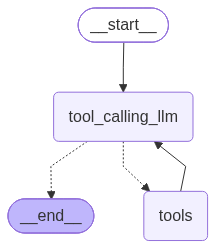

In [ ]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
graph_memory = builder.compile(checkpointer=memory)

# View
display(Image(graph_memory.get_graph().draw_mermaid_png()))

In [ ]:
## Specify the thread

config={"configurable":{"thread_id":"1"}}
# Specify an input
messages = [HumanMessage(content="Add 12 and 13.")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================
Tool Calls:
  add (9d07e32e-a875-4f41-90f0-82eac2a4ad0b)
 Call ID: 9d07e32e-a875-4f41-90f0-82eac2a4ad0b
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================


In [ ]:
messages = [HumanMessage(content="add that number to 25")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================
Tool Calls:
  add (9d07e32e-a875-4f41-90f0-82eac2a4ad0b)
 Call ID: 9d07e32e-a875-4f41-90f0-82eac2a4ad0b
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

25 + 25 = 50.


In [ ]:
messages = [HumanMessage(content="then multiplty that number by 2")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================
Tool Calls:
  add (9d07e32e-a875-4f41-90f0-82eac2a4ad0b)
 Call ID: 9d07e32e-a875-4f41-90f0-82eac2a4ad0b
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

25 + 25 = 50.
================================ Human Message =================================

then multiplty that number by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (d6a6175d-42ee-4147-b262-2aa5e9e04057)
 Call ID: d6a6175d-42ee-4147-b262-2aa5e9e04057
  Args:
  